# Anatomical Brain Model from MPRAGE

Calvin Woehrle

Load the high-resolution T1-weighted **MPRAGE** scan and build an anatomical
model of the brain:

1. Header inspection (shape, voxel size, orientation).
2. Standard 2D anatomical views (axial montage + ortho).
3. A **3D whole-head surface model** reconstructed with marching cubes.
4. A **3D brain-only model** after morphological skull stripping.


In [2]:
from pathlib import Path
from typing import cast

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from nibabel.nifti1 import Nifti1Image
from nilearn import plotting

NIIX_DIR = Path("niix")
# MPRAGE_GRAPPA2_6 is the distortion-corrected T1 anatomical scan.
MPRAGE = NIIX_DIR / "MPRAGE_GRAPPA2_6.nii"


def load(path: Path) -> Nifti1Image:
    return cast(Nifti1Image, nib.load(path))


img = load(MPRAGE)
data = img.get_fdata()  # shape (X, Y, Z) -- a single 3D volume
zooms = img.header.get_zooms()

print(f"File:        {MPRAGE.name}")
print(f"Shape:       {img.shape}  (X, Y, Z)")
print(f"Voxel size:  {tuple(round(z, 2) for z in zooms[:3])} mm")
print(f"Orientation: {''.join(nib.aff2axcodes(img.affine))}")
print(f"Intensity:   min={data.min():.0f}  max={data.max():.0f}")


File:        MPRAGE_GRAPPA2_6.nii
Shape:       (176, 256, 256)  (X, Y, Z)
Voxel size:  (np.float32(1.0), np.float32(1.0), np.float32(1.0)) mm
Orientation: RAS
Intensity:   min=0  max=905


## 2D anatomical views

`plot_anat` renders the T1 volume in the subject's own space. The axial montage
walks up through the brain; the ortho view shows all three planes at once.


/var/folders/s6/wjts5w1x76j6ghksybvlcwcm0000gn/T/ipykernel_83242/2408027069.py:4: UserWarning: Casting data from int32 to float32
  plotting.plot_anat(
/var/folders/s6/wjts5w1x76j6ghksybvlcwcm0000gn/T/ipykernel_83242/2408027069.py:15: UserWarning: Casting data from int32 to float32
  plotting.plot_anat(


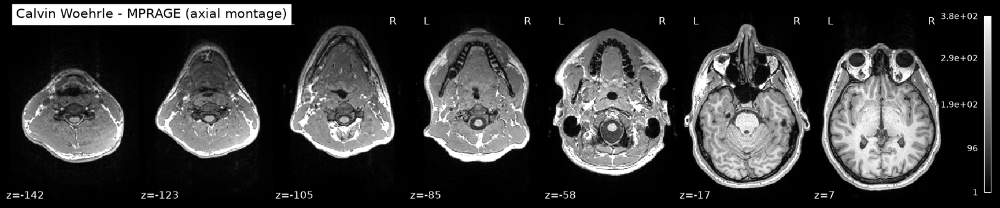

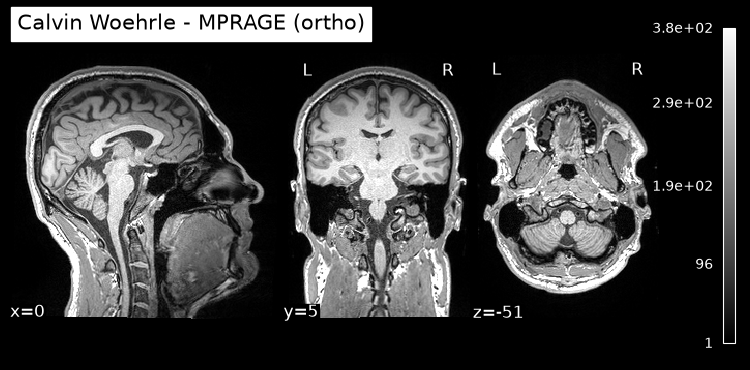

In [3]:
# Robust intensity window so faint tissue isn't washed out by a few bright voxels.
vmin, vmax = np.percentile(data[data > 0], [2, 98])

plotting.plot_anat(
    img,
    title="Calvin Woehrle - MPRAGE (axial montage)",
    display_mode="z",
    cut_coords=7,
    vmin=vmin,
    vmax=vmax,
    draw_cross=False,
    annotate=True,
)

plotting.plot_anat(
    img,
    title="Calvin Woehrle - MPRAGE (ortho)",
    display_mode="ortho",
    vmin=vmin,
    vmax=vmax,
    draw_cross=False,
)

plotting.show()


## 3D whole-head surface model

Threshold the volume to separate head tissue from air, keep the largest
connected component (the whole head), then run **marching cubes** to extract a
triangular mesh of the outer scalp surface. The mesh is plotted in true
millimetre coordinates using the voxel spacing.


Mesh: 56,044 vertices, 111,738 triangles


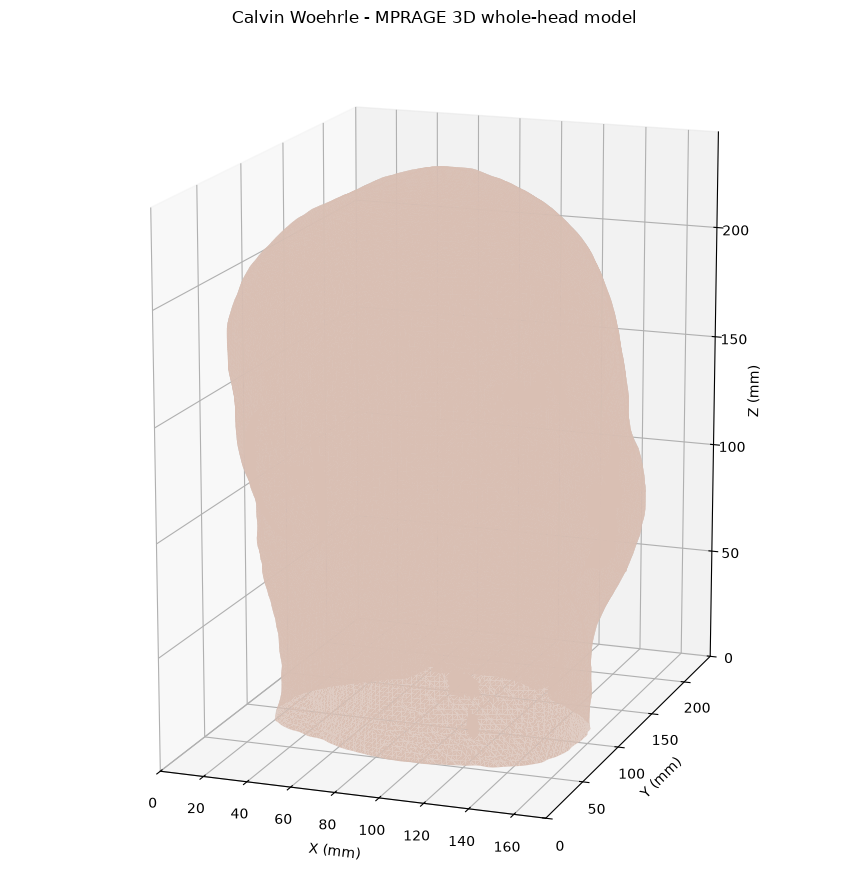

In [4]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy import ndimage
from skimage import measure

# 1. Downsample for a responsive mesh (full-res works too, just slower).
step = 2
vol = data[::step, ::step, ::step]
spacing = tuple(float(z) * step for z in zooms[:3])

# 2. Threshold head vs. air, then clean the mask up.
thr = np.percentile(vol[vol > 0], 55)
mask = ndimage.binary_fill_holes(vol > thr)

# 3. Keep only the largest connected component (the head).
labels, n = ndimage.label(mask)
if n > 1:
    largest = np.argmax(np.bincount(labels.ravel())[1:]) + 1
    mask = labels == largest

# 4. Light smoothing for a cleaner surface, then extract the mesh.
smooth = ndimage.gaussian_filter(mask.astype(float), sigma=1.0)
verts, faces, normals, _ = measure.marching_cubes(smooth, level=0.5, spacing=spacing)
print(f"Mesh: {len(verts):,} vertices, {len(faces):,} triangles")

# 5. Render the surface.
fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")
mesh = Poly3DCollection(verts[faces], alpha=1.0)
mesh.set_facecolor((0.85, 0.75, 0.70))
mesh.set_edgecolor("none")
ax.add_collection3d(mesh)

ax.set_xlim(0, verts[:, 0].max())
ax.set_ylim(0, verts[:, 1].max())
ax.set_zlim(0, verts[:, 2].max())
ax.set_box_aspect(
    (np.ptp(verts[:, 0]), np.ptp(verts[:, 1]), np.ptp(verts[:, 2]))
)
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.set_title("Calvin Woehrle - MPRAGE 3D whole-head model")
ax.view_init(elev=15, azim=-70)
plt.tight_layout()
plt.show()


## Brain-only 3D model (skull stripping)

The surface above is the scalp/skull. To model the **brain** itself, remove the
outer tissue with a classic morphological extraction:

1. Threshold to a tissue mask.
2. **Erode** hard to snap the thin bridges joining brain, skull and scalp.
3. Keep the largest surviving blob &mdash; the brain core.
4. **Dilate** back to the original size, clipped to the tissue mask.

Then reconstruct the surface with marching cubes.


Brain mask keeps 30% of the tissue voxels
Brain mesh: 27,690 vertices, 55,368 triangles


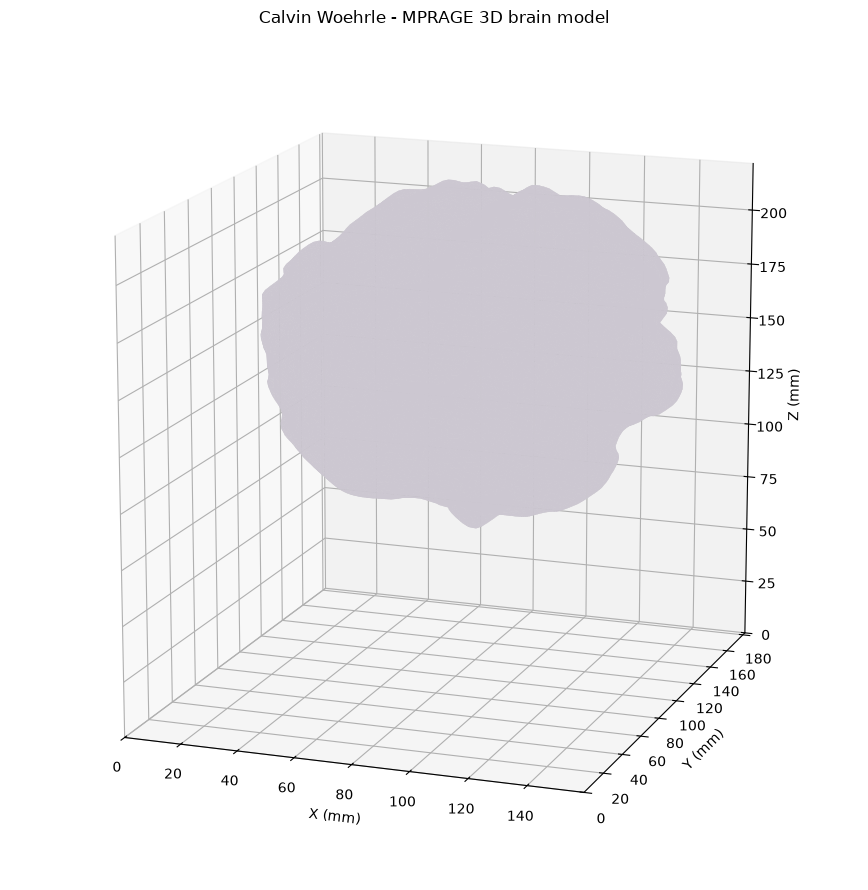

In [5]:
# Work on the 2mm downsampled volume from the previous cell (vol, spacing).
# In T1 the skull (compact bone) is dark, so a plain intensity threshold leaves
# a gap between the bright brain and the bright scalp. Do NOT fill that gap here.
tissue = vol > np.percentile(vol[vol > 0], 60)

# 1. Erode to snap the thin bridges (orbits, skull base) joining brain & scalp.
erode_iters = 4
core = ndimage.binary_erosion(tissue, iterations=erode_iters)

# 2. Largest connected component of the eroded mask = brain core.
labels, n = ndimage.label(core)
sizes = np.bincount(labels.ravel())
sizes[0] = 0  # ignore background
brain_core = labels == sizes.argmax()

# 3. Dilate the core back out, staying inside the tissue mask, then fill.
brain = ndimage.binary_dilation(brain_core, iterations=erode_iters) & tissue
brain = ndimage.binary_fill_holes(brain)

frac = 100 * brain.sum() / tissue.sum()
print(f"Brain mask keeps {frac:.0f}% of the tissue voxels")

# 4. Smooth and mesh the brain surface.
brain_smooth = ndimage.gaussian_filter(brain.astype(float), sigma=1.0)
bverts, bfaces, _, _ = measure.marching_cubes(brain_smooth, level=0.5, spacing=spacing)
print(f"Brain mesh: {len(bverts):,} vertices, {len(bfaces):,} triangles")

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")
bmesh = Poly3DCollection(bverts[bfaces], alpha=1.0)
bmesh.set_facecolor((0.80, 0.78, 0.82))
bmesh.set_edgecolor("none")
ax.add_collection3d(bmesh)

ax.set_xlim(0, bverts[:, 0].max())
ax.set_ylim(0, bverts[:, 1].max())
ax.set_zlim(0, bverts[:, 2].max())
ax.set_box_aspect(
    (np.ptp(bverts[:, 0]), np.ptp(bverts[:, 1]), np.ptp(bverts[:, 2]))
)
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.set_title("Calvin Woehrle - MPRAGE 3D brain model")
ax.view_init(elev=15, azim=-70)
plt.tight_layout()
plt.show()


## Interactive HTML viewer

`nilearn.plotting.view_img` builds a self-contained, draggable orthographic
viewer. Click and drag inside the panels to move the cross-hair through the
brain. The viewer is pure HTML/JS, so it also works when the notebook is
exported to HTML.


/var/folders/s6/wjts5w1x76j6ghksybvlcwcm0000gn/T/ipykernel_83242/2070710900.py:3: UserWarning: Casting data from int32 to float32
  html_view = plotting.view_img(



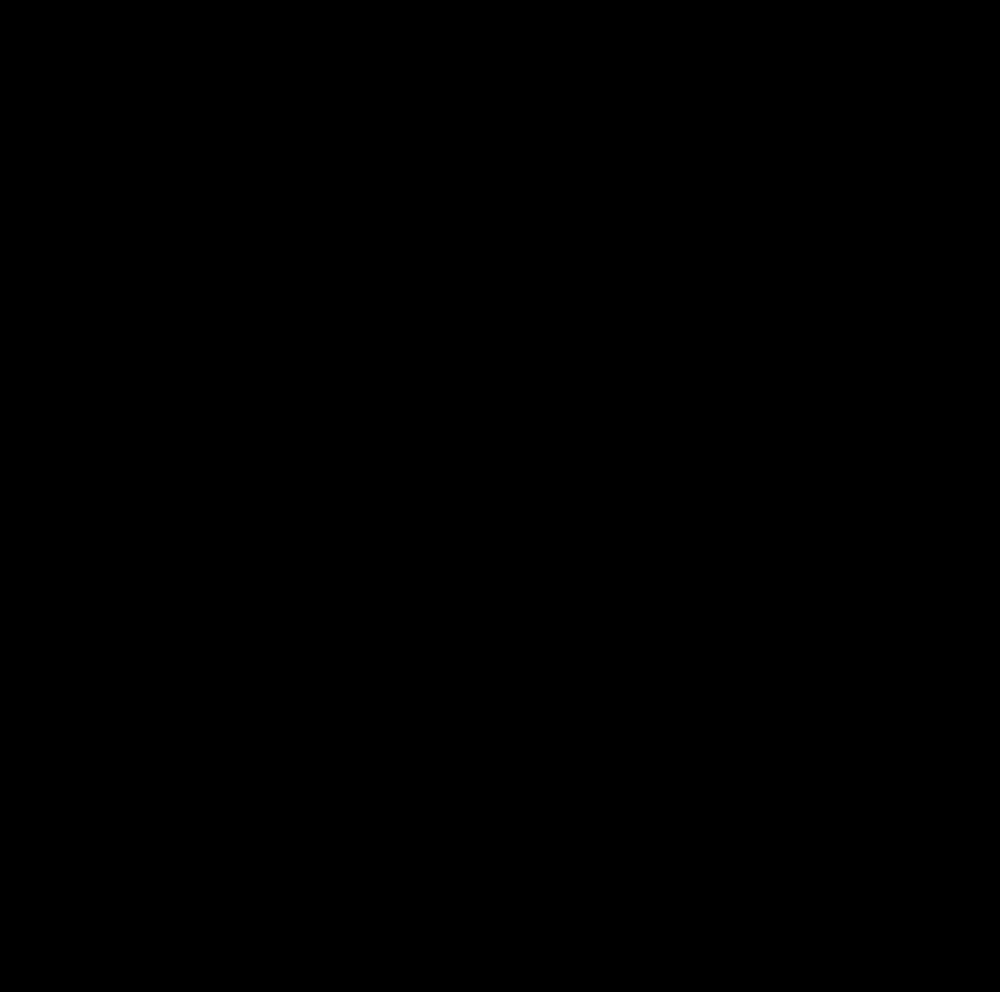
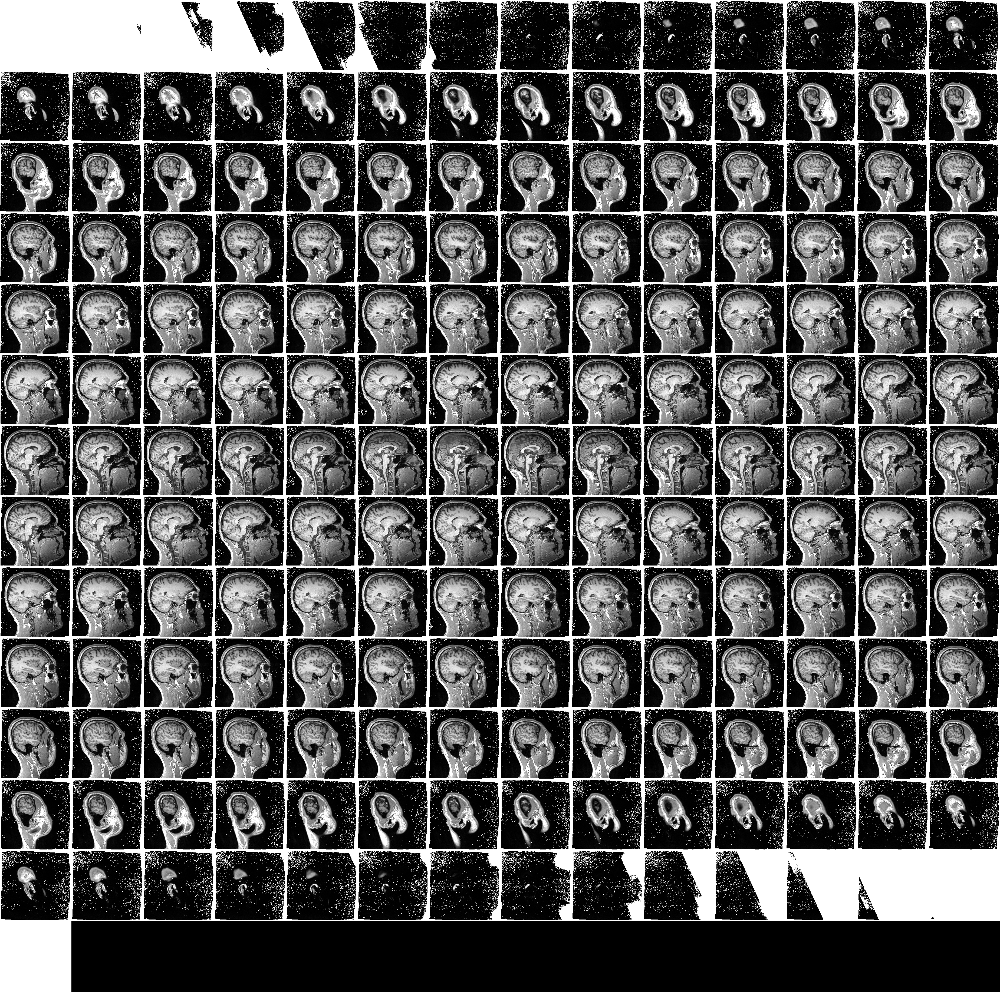

In [6]:
# Draggable ortho viewer of the T1 volume. Use bg_img=None so the MPRAGE itself
# is the background, and match the robust intensity window from earlier.
html_view = plotting.view_img(
    img,
    bg_img=None,
    cmap="gray",
    symmetric_cmap=False,
    vmin=vmin,
    vmax=vmax,
    black_bg=True,
    title="Calvin Woehrle - MPRAGE interactive viewer",
)

# Optionally save a standalone HTML file you can open in any browser:
html_view.save_as_html("mprage_viewer.html")

html_view


## Interactive 3D head model

The whole-head surface above is a static render. Here the same marching-cubes
mesh (`verts`, `faces`) is drawn with **Plotly**, so you can **click-drag to
rotate**, scroll to zoom, and right-drag to pan the model in real time.


In [7]:
import plotly.graph_objects as go

# Reuse the whole-head mesh from the marching-cubes cell above.
x, y, z = verts.T
i, j, k = faces.T

head = go.Mesh3d(
    x=x, y=y, z=z,
    i=i, j=j, k=k,
    color="rgb(217, 191, 179)",
    opacity=1.0,
    lighting=dict(ambient=0.45, diffuse=0.9, specular=0.3, roughness=0.5),
    lightposition=dict(x=200, y=200, z=400),
    flatshading=False,
    name="head",
)

fig = go.Figure(data=[head])
fig.update_layout(
    title="Calvin Woehrle - Interactive 3D head model",
    width=800,
    height=800,
    scene=dict(
        xaxis_title="X (mm)",
        yaxis_title="Y (mm)",
        zaxis_title="Z (mm)",
        aspectmode="data",  # keep true anatomical proportions
    ),
    margin=dict(l=0, r=0, t=40, b=0),
)

# Optionally save a standalone, shareable HTML file:
# fig.write_html("head_model.html")

fig.show()


## Export to STL

The marching-cubes mesh (`verts`, `faces`) is already a watertight triangle
surface, so it can be written directly to an **STL** file for 3D printing or
viewing in any CAD/mesh tool. Coordinates are in millimetres, so the print
comes out life-size.


In [8]:
def write_binary_stl(path, verts, faces):
    """Write a triangle mesh to a binary STL file (units = mm)."""
    tris = verts[faces]  # (n_faces, 3, 3): each triangle's 3 xyz vertices

    # Per-face normal from the triangle edges.
    normals = np.cross(tris[:, 1] - tris[:, 0], tris[:, 2] - tris[:, 0])
    lengths = np.linalg.norm(normals, axis=1, keepdims=True)
    normals = np.divide(normals, lengths, out=np.zeros_like(normals), where=lengths > 0)

    n = len(faces)
    record = np.zeros(
        n,
        dtype=np.dtype([
            ("normal", "<f4", 3),
            ("v", "<f4", (3, 3)),
            ("attr", "<u2"),
        ]),
    )
    record["normal"] = normals
    record["v"] = tris

    with open(path, "wb") as f:
        f.write(b"MPRAGE head model - Calvin Woehrle".ljust(80, b" "))
        f.write(np.uint32(n).tobytes())
        f.write(record.tobytes())
    return path


stl_path = "head_model.stl"
write_binary_stl(stl_path, verts, faces)
print(f"Wrote {stl_path}: {len(faces):,} triangles, {len(verts):,} vertices")


Wrote head_model.stl: 111,738 triangles, 56,044 vertices
